## Module 4 Project

### Submit this code as a pull request back to GitHub Classroom by the date and time listed in Canvas.

For this assignment, use the ERA-5 monthly mean data at NCAR (DOI: 10.5065/P8GT-0R61) as we did in Module 2. Feel free to reduce the data to 1 degree resolution if you need to save data download times.

1. Create a dataset that contains the monthly means of Sea Surface Temperature anomalies and total column water vapor from Jan 1979-Dec 2024 over the Pacific Basin (65°N to 65°S, 120°E to 60°W) masked out over land - save this to your computer. The data and land sea mask is available here: https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download

2. From the dataset shown in 1, compute anomalies by deseasonalizing the data (remove the mean monthly anomaly from the annual mean from each point) and detrend the data.

Then, standardize the SST anomalies. Standardization means subtract the long term mean and divide by the standard deviation, which can be accomplished using the methods described here: 6.3. Preprocessing data — scikit-learn 1.1.2 documentation

3. Perform an EOF analysis on the SST anomalies and plot a map of the first 5 EOFs, following M04N05.

4. Plot the percent of variance explained by the first 10 EOFs.

5. Reconstruct the SST field using the first 5 EOFs and plot a map of the Pearson's correlation coefficient (xarray.corr) of the reconstructed monthly time series and the "observed" SST time series.

6. Compute a map of the Pearson's correlation coefficient between SST EOF1 and monthly mean detrended, deseasonalized, and standardized monthly mean column water vapor anomalies (don't mask these over land for the plot). See anything interesting?


In [2]:
!pip install "cdsapi>=0.7.7"

  Attempting uninstall: multiurl
    Found existing installation: multiurl 0.3.5
    Uninstalling multiurl-0.3.5:
      Successfully uninstalled multiurl-0.3.5
  Attempting uninstall: ecmwf-datastores-client
    Found existing installation: ecmwf-datastores-client 0.2.0
    Uninstalling ecmwf-datastores-client-0.2.0:
      Successfully uninstalled ecmwf-datastores-client-0.2.0
  Attempting uninstall: cdsapi
    Found existing installation: cdsapi 0.7.6
    Uninstalling cdsapi-0.7.6:
      Successfully uninstalled cdsapi-0.7.6
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [cdsapi]


In [53]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cdsapi
from eofs.xarray import Eof
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from sklearn.decomposition import PCA
import xarray as xr

In [8]:
# As directed by CDSAPI - https://cds.climate.copernicus.eu/how-to-api
home = Path.home()
cds_file = home / ".cdsapirc"

# Replace YOUR_KEY_HERE with your actual key from CDS website
cds_content = """url: https://cds.climate.copernicus.eu/api
key: 6862ddb7-08d7-4b2d-910a-6af9f1ff3f5b
"""

cds_file.write_text(cds_content)
print(f"✅ Created {cds_file}")

✅ Created /Users/Billiam/.cdsapirc


In [59]:
# Use CDS API to download data

client = cdsapi.Client()

dataset = "reanalysis-era5-single-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": [
        "sea_surface_temperature",
        "total_column_water_vapour"
    ],
    "year": [
        "1979", "1980", "1981",
        "1982", "1983", "1984",
        "1985", "1986", "1987",
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024"
    ],
    "month": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12"
    ],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived",
    "area": [65, 120, -65, 300]
}

client.retrieve(dataset, request).download()

2025-10-10 04:51:41,368 INFO Request ID is 0faecd7d-4f7a-48cf-9faf-4c22fa71e179
2025-10-10 04:51:41,551 INFO status has been updated to accepted
2025-10-10 04:51:50,665 INFO status has been updated to running
2025-10-10 04:54:35,633 INFO status has been updated to successful


64462b51af9f69d5a3c1f36593a82bcc.nc:   0%|          | 0.00/537M [00:00<?, ?B/s]

'64462b51af9f69d5a3c1f36593a82bcc.nc'

In [78]:
def _time_as_float(time: xr.DataArray, time_dim: str) -> xr.DataArray:
    # Numeric seconds since first timestamp (keeps numbers small)
    return (time - time.isel({time_dim: 0})).astype("timedelta64[s]").astype("int64").astype("float64")

def linear_detrend(obj: xr.DataArray | xr.Dataset, time_dim: str = "time") -> xr.DataArray | xr.Dataset:
    """
    Remove a linear trend y ~ s*(t - t̄_valid) + ȳ_valid at each grid point.
    Closed-form LS using reductions; dask-friendly; handles NaNs.
    """
    t = _time_as_float(obj[time_dim], time_dim)  # (time, )
    def _detrend_da(da: xr.DataArray) -> xr.DataArray:
        da = da.sortby(time_dim).astype("float32")
        if hasattr(da.data, "chunks"):
            da = da.chunk({time_dim: -1})  # One chunk along time
        mask = da.notnull()                                # (time, ...)
        t_b = t.broadcast_like(da)                         # (time, ...)
        t_mean_valid = t_b.where(mask).mean(time_dim, skipna = True)
        tc = t_b - t_mean_valid                            # Centered time per point
        num = (da * tc).sum(time_dim, skipna = True)
        den = (tc**2).sum(time_dim, skipna = True)
        slope = xr.where(den > 0, num / den, 0.0)
        ybar  = da.mean(time_dim, skipna = True)
        trend = slope * (t_b - t_mean_valid) + ybar
        return (da - trend).astype("float32")
    return obj.map(_detrend_da) if isinstance(obj, xr.Dataset) else _detrend_da(obj)

def monthly_anom_and_z(
    detr: xr.DataArray | xr.Dataset,
    time_dim: str = "time",
    base_period: tuple[str, str] | None = None,
    ddof: int = 1,
    eps: float = 1e-6,
):
    """
    From linearly-detrended data, remove monthly climatology and compute monthly z-scores.
    Returns (anom, z). Works for Dataset or DataArray.
    """
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)})
    key = f"{time_dim}.month"

    clim_mean = clim_src.groupby(key).mean(time_dim, skipna = True)
    anom = detr.groupby(key) - clim_mean

    clim_std = clim_src.groupby(key).std(time_dim, skipna = True, ddof = ddof)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan)
    z = anom.groupby(key) / safe_std
    return anom, z

In [79]:
# Check Dataset
ds = xr.open_dataset("64462b51af9f69d5a3c1f36593a82bcc.nc")
print(ds)

<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    expver      (valid_time) <U4 9kB ...
Data variables:
    sst         (valid_time, latitude, longitude) float32 829MB ...
    tcwv        (valid_time, latitude, longitude) float32 829MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-10T09:53 GRIB to CDM+CF via cfgrib-0.9.1...


In [80]:
# Part 2: Compute Anomalies, Deseasonalize and Detrend
# Following Github example
ds = ds.chunk({"valid_time": -1}) 

# Use functions provided
detr = linear_detrend(ds, time_dim = "valid_time")
anom, z = monthly_anom_and_z(detr, time_dim = "valid_time", base_period = ("1981-01-01", "2010-12-31"))

In [81]:
# Part 2: EOF Analysis Using Sci-Kit Learn
# Flatten spatial dims for PCA
sst_anom = anom["sst"]
n_time = sst_anom.sizes["valid_time"]
sst_flat = sst_anom.stack(space = ("latitude", "longitude")).values

# Remove grid points with NaNs
valid = ~np.any(np.isnan(sst_flat), axis = 0)
sst_flat_valid = sst_flat[:, valid]

# EOF analysis
n_modes = 10
pca = PCA(n_components = n_modes)
pc = pca.fit_transform(sst_flat_valid)

# Initialize EOF array for full grid
n_space = sst_flat.shape[1]
eofs = np.full((n_space, n_modes), np.nan)

# Assign PCA EOFs to valid points only
eofs[valid, :] = pca.components_.T[:, :n_modes]

In [64]:
print("sst_flat shape:", sst_flat.shape)
print("valid points:", valid.sum())
print("pca.components_.T shape:", pca.components_.T.shape)

sst_flat shape: (552, 375641)
valid points: 301472
pca.components_.T shape: (301472, 10)


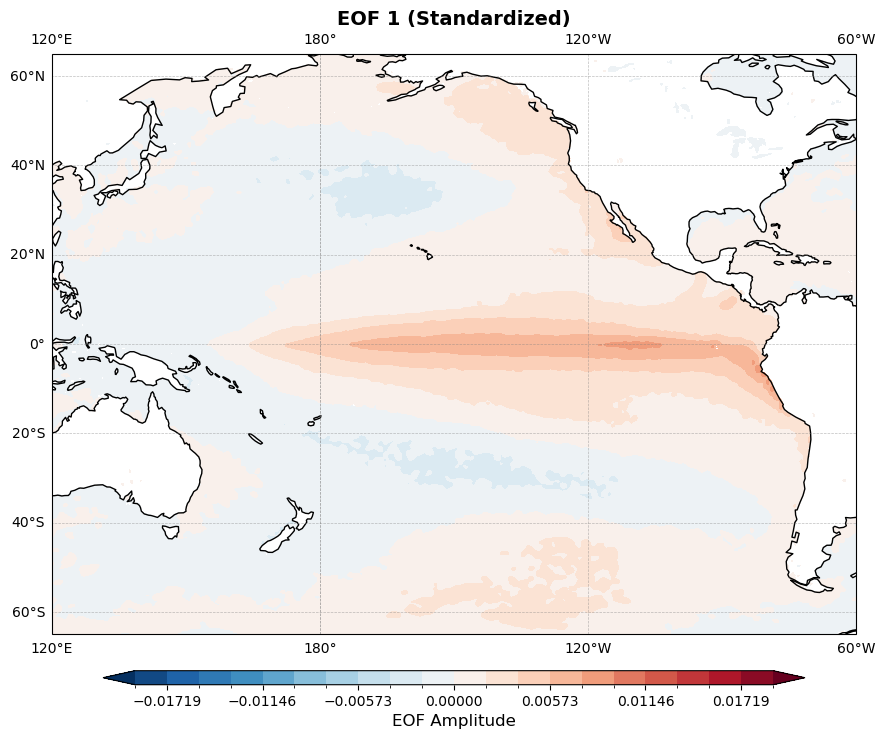

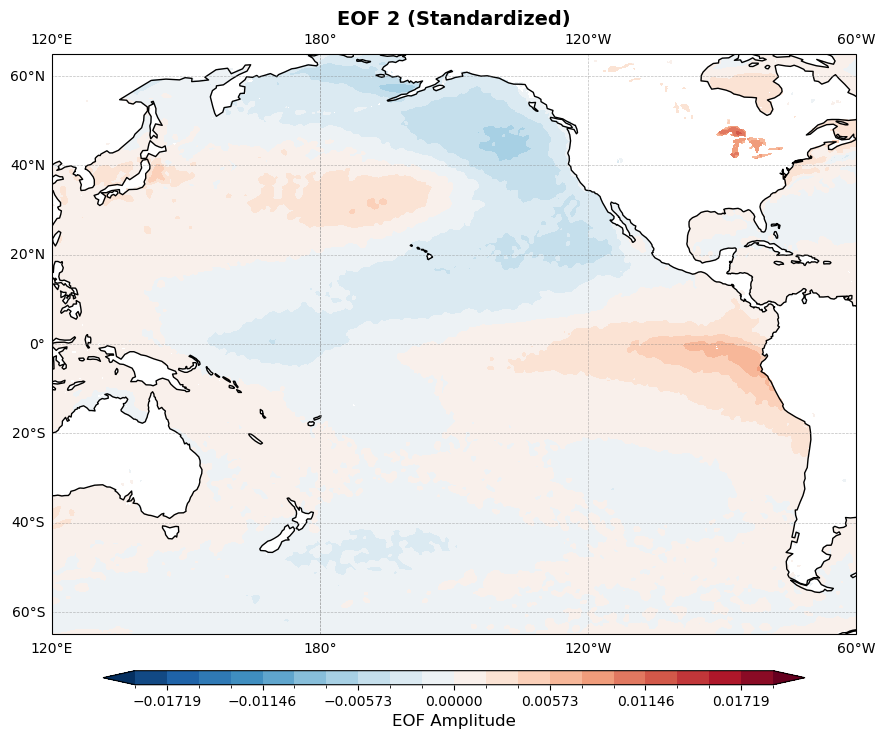

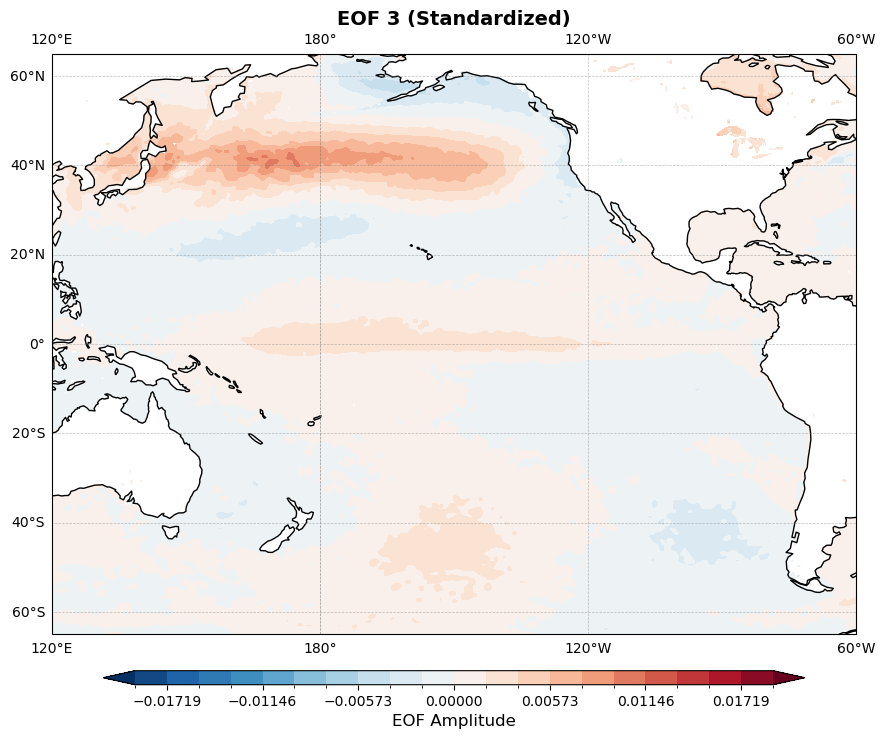

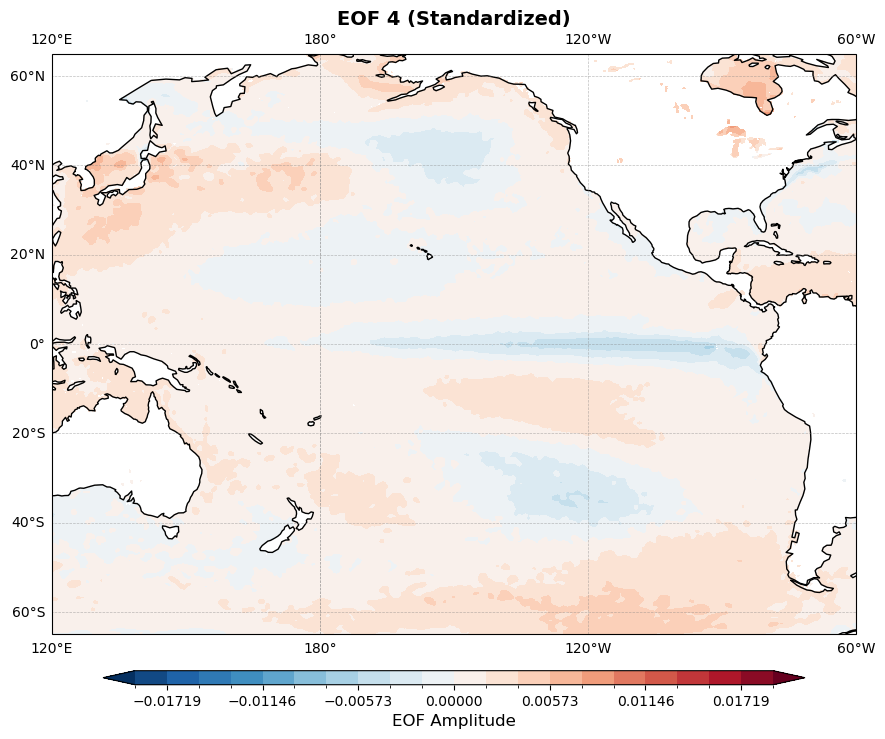

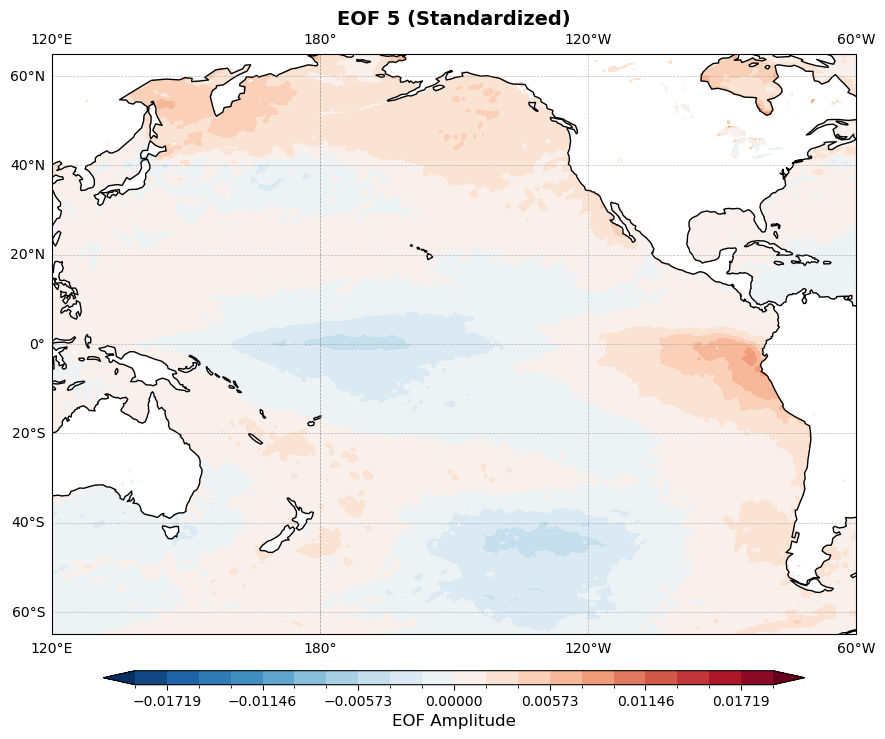

In [69]:
# Plot First 5 EOFs
n_eofs = 5
lat_bounds = [-65, 65]
lon_bounds = [120, 300]  # 120E → 60W in 0–360° coordinates

# Color levels
valid_vals = eofs[~np.isnan(eofs)].flatten()
clevs = np.linspace(-np.max(np.abs(valid_vals)), np.max(np.abs(valid_vals)), 21)

# Ensure longitude in dataset is 0–360
lon = sst_anom.longitude.values
if np.any(lon < 0):
    sst_anom = sst_anom.assign_coords(longitude = (sst_anom.longitude % 360))
    
for i in range(n_eofs):
    eof_i = eofs[:, i]
    
    # Reshape and mask invalid points
    eof_map = xr.DataArray(
        np.where(np.isnan(eof_i.reshape(sst_anom.latitude.size, sst_anom.longitude.size)), 
                 np.nan, 
                 eof_i.reshape(sst_anom.latitude.size, sst_anom.longitude.size)),
        coords = [sst_anom.latitude, sst_anom.longitude],
        dims = ["latitude", "longitude"]
    )

    # Figure 
    plt.figure(figsize = (12, 8))
    ax = plt.axes(projection = ccrs.PlateCarree(central_longitude = 180))
    
    # Extent
    ax.set_extent([120, 300, -65, 65], crs = ccrs.PlateCarree())

    # Plot EOF
    eof_plot = eof_map.plot.contourf(ax = ax, levels = clevs, cmap = "RdBu_r", extend = "both", add_colorbar = False,
                                     transform = ccrs.PlateCarree())

    # Features
    ax.add_feature(cfeature.COASTLINE, linewidth = 1)
    ax.gridlines(draw_labels = True, linewidth = 0.5, color = 'gray', alpha = 0.5, linestyle = '--')

    # Colorbar
    cbar = plt.colorbar(eof_plot, orientation = 'horizontal', pad = 0.05, aspect = 50, shrink = .60)
    cbar.set_label('EOF Amplitude', fontsize = 12)

    # Title
    plt.title(f'EOF {i+1} (Standardized)', fontsize = 14, weight = 'bold')

    plt.tight_layout()
    plt.show()

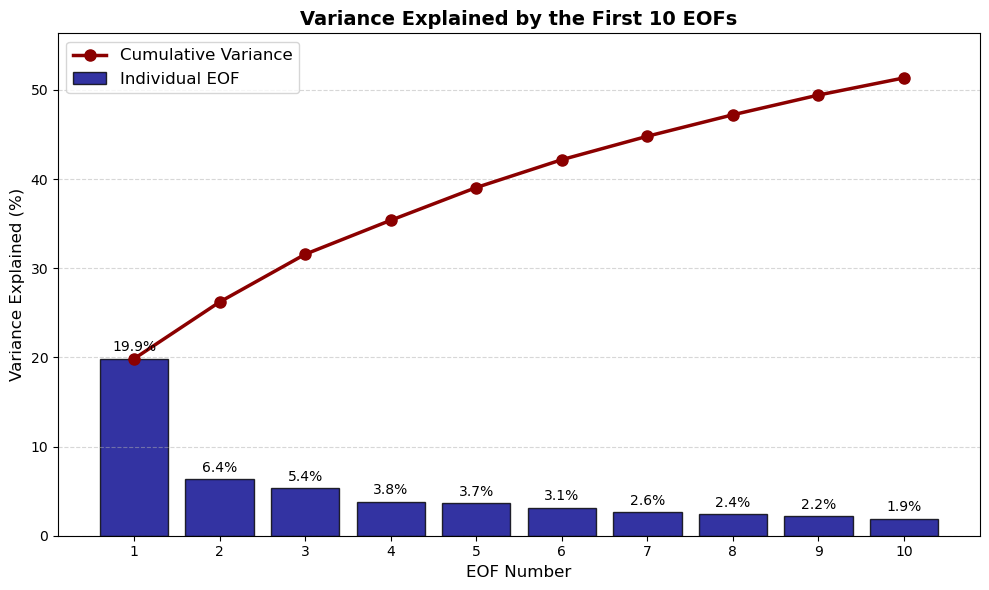

In [75]:
# Part 4: Plot Percent of Variance explained by first 10 EOFs

# Variance
var_frac = pca.explained_variance_ratio_
var_percent = var_frac[0:10] * 100
cum_var = np.cumsum(var_percent)
eof_num = np.arange(1, 11)

plt.figure(figsize = (10, 6))

# EOF Bar Plot
bars = plt.bar(eof_num, var_percent, color = "darkblue", edgecolor = 'k', alpha = 0.8, label = 'Individual EOF')

# Bar labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.5, f'{height:.1f}%', ha = 'center', va = 'bottom', fontsize = 10)

# Plot Cumulative Variance
plt.plot(eof_num, cum_var, color = "darkred", linewidth = 2.5, marker = 'o', markersize = 8, label = 'Cumulative Variance')

# Deets
plt.xticks(eof_num)
plt.xlabel('EOF Number', fontsize = 12)
plt.ylabel('Variance Explained (%)', fontsize = 12)
plt.title('Variance Explained by the First 10 EOFs', fontsize = 14, weight = 'bold')
plt.grid(axis = 'y', linestyle = '--', alpha = 0.5)

# Add legend
plt.legend(fontsize = 12)

# Tight layout for clean look
plt.ylim(0, max(cum_var) + 5)
plt.tight_layout()
plt.show()

In [82]:
# Part 5: Reconstruct SSTs using first 5 EOFs, Pearson Correlation plot, and reconstructed observed time series
n_eof = 5
sst_recon_flat = pc[:, :n_eof] @ eofs[valid, :n_eof].T
sst_recon = np.full(sst_flat.shape, np.nan)
sst_recon[:, valid] = sst_recon_flat

# Reshape back to original grid
sst_recon_da = xr.DataArray(sst_recon.reshape(sst_anom.shape), coords = sst_anom.coords, dims = sst_anom.dims)

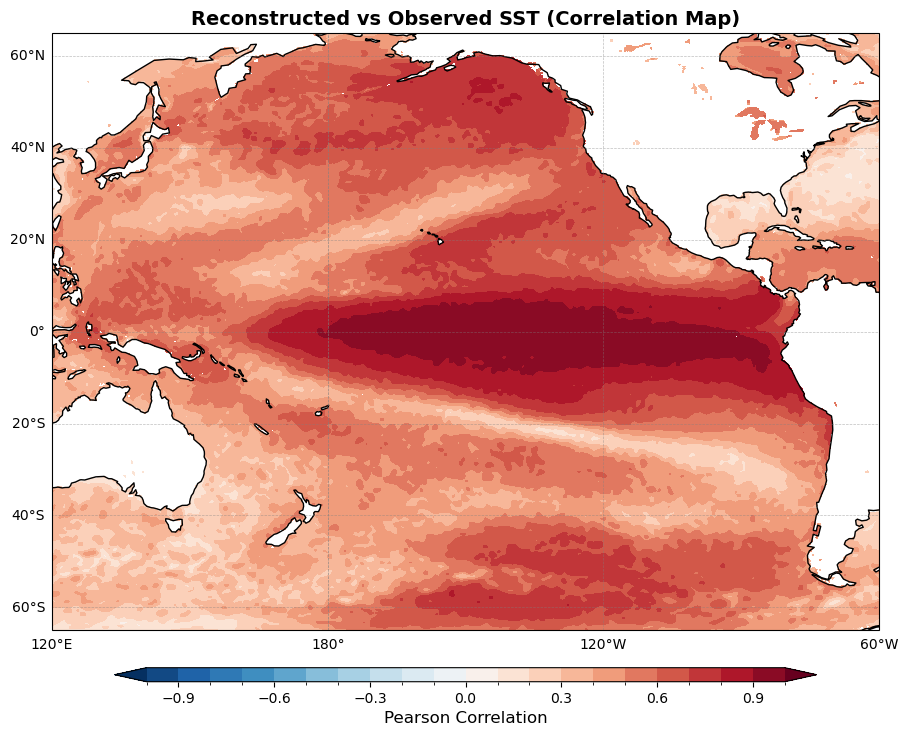

In [90]:
# Correlation map between reconstructed and original
corr_map = xr.corr(sst_anom, sst_recon_da, dim = "valid_time")

plt.figure(figsize = (12, 8))
ax = plt.axes(projection = ccrs.PlateCarree(central_longitude = 180))

# Plot correlation
cmap = plt.cm.RdBu_r
clevs = np.linspace(-1, 1, 21)
corr = corr_map.plot.contourf(ax = ax, levels = clevs, cmap = cmap, extend = "both", add_colorbar = False, transform = ccrs.PlateCarree())

# Features
ax.add_feature(cfeature.COASTLINE, linewidth = 1)
gl = ax.gridlines(draw_labels = True, linewidth = 0.5, color = 'gray', alpha = 0.5, linestyle = '--')
gl.top_labels = False
gl.right_labels = False

# Extent
ax.set_extent([120, 300, -65, 65], crs = ccrs.PlateCarree())

# Colorbar
cbar = plt.colorbar(corr, orientation = 'horizontal', pad = 0.05, aspect = 50, shrink = .60)
cbar.set_label('Pearson Correlation', fontsize = 12)

# Title
plt.title("Reconstructed vs Observed SST (Correlation Map)", fontsize = 14, weight = 'bold')
plt.tight_layout()
plt.show()

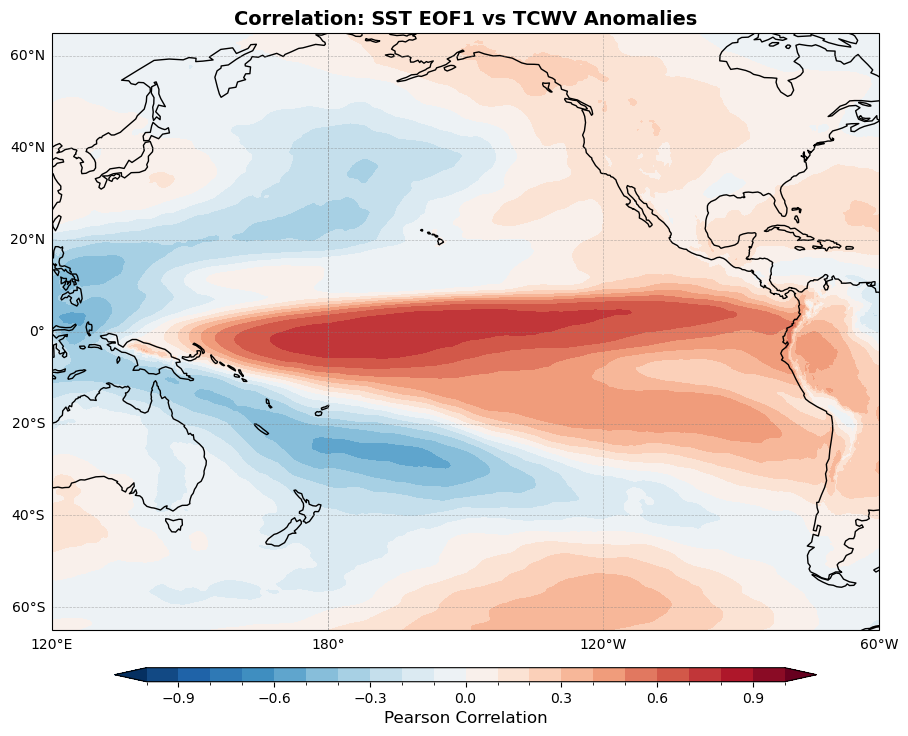

In [94]:
# Part 6: Plot Pearson Correlation between SST EOF 1 and detrended/standardized TCWV anomaly
sst_eof1 = pc[:, 0]  # EOF1 PC time series
tcwv_anom = z["tcwv"]  # Standardized Anomalies

corr_tcwv = xr.corr(tcwv_anom, xr.DataArray(sst_eof1, coords = [tcwv_anom.valid_time], dims = ["valid_time"]), dim = "valid_time")

# Correlation between SST EOF1 and TCWV anomalies
plt.figure(figsize = (12, 8))
ax = plt.axes(projection = ccrs.PlateCarree(central_longitude = 180))

clevs = np.linspace(-1, 1, 21)
corr2 = corr_tcwv.plot.contourf(ax = ax, levels = clevs, cmap = "RdBu_r", extend = "both", add_colorbar = False,
                               transform = ccrs.PlateCarree())

# Features
ax.add_feature(cfeature.COASTLINE, linewidth = 1)
gl = ax.gridlines(draw_labels = True, linewidth = 0.5, color = 'gray', alpha = 0.5, linestyle = '--')
gl.top_labels = False
gl.right_labels = False

# Extent
ax.set_extent([120, 300, -65, 65], crs = ccrs.PlateCarree())

# Colorbar
cbar = plt.colorbar(corr2, orientation = 'horizontal', pad = 0.05, aspect = 50, shrink = .60)
cbar.set_label('Pearson Correlation', fontsize = 12)

# Title
plt.title("Correlation: SST EOF1 vs TCWV Anomalies", fontsize = 14, weight = 'bold')
plt.tight_layout()
plt.show()